# 4 · Results for the CISO: explanations, drift, business impact, recommendations
All numbers use the **frozen Phase 6 model** on the test period. Notebooks: [1 data](1_data.ipynb) · [2 train & validate](2_train_validate.ipynb) · [3 test](3_test.ipynb) · [4 results for the CISO](4_results_ciso.ipynb) · [5 CISO tool](5_ciso_tool.ipynb) · detailed appendices in `appendix/`.

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "mpl")); os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
TAB, FIG = ROOT / "outputs" / "tables", ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, AQUA, VIOLET, RED, INK, INK2, GRID, SURF = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#d64545", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "font.size": 9.5})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
def T(name, **kw): return pd.read_csv(TAB / f"{name}.csv", **kw)
def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
pt = lambda s: float(str(s).split()[0])
HEAD, ALT, EPSS7 = "gradient boosting (headline)", "late fusion (alternative)", 'EPSS (first score, <=7 d after pub)'

## 4.1 Why the model ranks what it ranks (SHAP)
Permutation SHAP on the 22 raw inputs (the standard tree explainer mis-handles the model's categorical CVSS splits;
these values add up exactly to the model output), 2,000 random test CVEs, log-odds units.

,group,mean |SHAP| random CVEs,mean |SHAP| exploited CVEs
feature,,,
CNA (who published),who: vendor / CNA / CWE,0.787,0.896
vendor KEV entries (all time),KEV history (vendor/product),0.645,1.135
CVSS score (CNA),CVSS (CNA),0.405,0.660
description length,text: phrase + length,0.355,0.357
CVSS PR,CVSS (CNA),0.353,0.370
CWE (CNA),who: vendor / CNA / CWE,0.305,0.268
vendor (or CNA),who: vendor / CNA / CWE,0.210,0.131
days since vendor's last KEV entry,KEV history (vendor/product),0.197,0.251
CVSS UI,CVSS (CNA),0.147,0.137


,example,cve_id,vendor,product,cvss_cna_score,cwe,label,days_to_kev,s_hgb,month_pct,in_top110
0,caught exploited CVE,CVE-2026-24858,Fortinet,FortiWeb,9.8,CWE-288,1,0.0,0.982973,1.000000,True
1,missed exploited CVE,CVE-2026-56155,Microsoft,Windows 10 Version 1607,7.8,CWE-1220,1,0.0,0.819655,0.935779,False
2,false alarm,CVE-2026-20079,Cisco,Cisco Secure Firewall Management Center (FMC),10.0,CWE-288,0,189.0,0.979038,1.000000,True


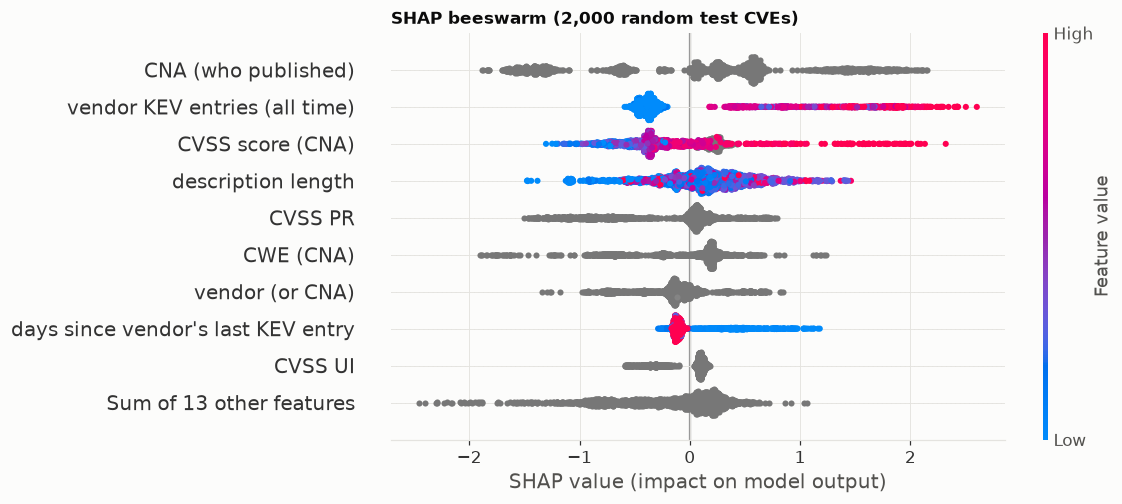

In [2]:
import shap
sh = pd.read_parquet(ROOT / "data" / "shap_test.parquet")
FEATS = [c[6:] for c in sh.columns if c.startswith("shap__")]; SV = sh[[f"shap__{f}" for f in FEATS]].to_numpy(); rand = sh["in_random"].to_numpy()
imp = T("07_shap_importance"); display(imp.head(10).set_index("feature"))
num = {f: pd.to_numeric(sh[f"x__{f}"], errors="coerce") for f in FEATS}
data = np.column_stack([num[f].to_numpy(float) if num[f].notna().any() else np.full(len(sh), np.nan) for f in FEATS])
names = dict(zip(imp["feature"], imp["feature"]))
NAME = {"vendor_key": "vendor (or CNA)", "cna": "CNA (who published)", "cwe": "CWE (CNA)", "n_cwes": "number of CWEs", "cvss_cna_score": "CVSS score (CNA)", "has_cna_cvss": "has CNA CVSS",
        "phrase_day0": "exploitation phrase (day 0)", "desc_len": "description length", "vendor_kev_log_all": "vendor KEV entries (all time)", "vendor_kev_log_365": "vendor KEV entries (365 d)",
        "vendor_kev_days_since": "days since vendor's last KEV entry", "vendor_kev_any": "vendor has any KEV entry", "product_kev_log_all": "product KEV entries", **{f"cvss_{p}": f"CVSS {p}" for p in ["AV", "AC", "PR", "UI", "S", "C", "I", "A", "AT"]}}
expl = shap.Explanation(values=SV[rand], base_values=sh.loc[rand, "base_value"].to_numpy(), data=data[rand], feature_names=[NAME[f] for f in FEATS])
plt.figure(); shap.plots.beeswarm(expl, max_display=10, show=False, plot_size=(9, 4.8)); plt.title("SHAP beeswarm (2,000 random test CVEs)", loc="left", fontweight="bold"); save(plt.gcf(), "4_01_beeswarm")
ex = T("07_examples"); display(ex[["example", "cve_id", "vendor", "product", "cvss_cna_score", "cwe", "label", "days_to_kev", "s_hgb", "month_pct", "in_top110"]])

**Takeaway**: **The model reads who is affected and whether attackers already target that vendor, then severity**: publisher (CNA, mean |SHAP| 0.79), the vendor's earlier KEV entries (0.65; the top driver for exploited CVEs, 1.14) and CNA CVSS (0.41). Examples: **caught** — Fortinet auth bypass CVE-2026-24858 (CVSS 9.8, Fortinet's 24 earlier KEV entries; #1 of its month, in KEV the same day); **missed** — Microsoft AD FS privilege escalation CVE-2026-56155 (local, 7.8; top 6.4% of a ~9,000-CVE month, outside the 110); **false alarm** — Cisco FMC auth bypass to root CVE-2026-20079 (CVSS 10), which *was* added to KEV, after 189 days.

## 4.2 Drift: why recall fell in 2026
> ⚠️ **Post-test exploratory analysis**: designed after the test results were seen; it explains them and changes no reported number.

year,2025,2026
positives,159,135
gradient boosting (headline) @110,41.9 [34–50],23.9 [17–32]
late fusion (alternative) @110,39.1 [31–47],17.8 [12–25]
"phrase, then CVSS (CNA) @110",29.5 [22–37],20.0 [13–27]
CVSS (CNA) ranking @110,19.2 [13–26],17.8 [11–25]
"EPSS (first score, <=7 d after pub) @110",29.6 [23–37],29.6 [21–37]
EPSS (score by day 1) @110,29.6 [23–37],29.6 [21–37]
random @110,2.7,1.7


,months,CVEs / month,exploited / month,K=110 as % of monthly CVEs,CVSS>=9 (CNA) / month,CVEs from vendors with earlier KEV entries / month
period,,,,,,
dev 2022-24,36,2606.7,8.9,4.2,123.8,695.7
2025,12,4012.5,13.2,2.7,237.5,1246.2
2026,8,6801.4,16.9,1.6,606.0,2375.8


year,2025,2026
random CVEs,900.00,1100.00
exploited CVEs,159.00,135.00
KEV group mean |SHAP| (random),0.82,0.98
KEV group share of all |SHAP| %,20.98,23.47
"KEV group mean SHAP, exploited",1.06,1.04
"KEV group mean SHAP, non-exploited (random)",0.00,0.23
% of non-exploited with KEV push > +1,18.75,26.64
% of exploited with KEV push > +1,54.09,59.26
rank of 'vendor KEV entries (365 d)',16.00,17.00


,positives,frozen @110,rolling @110,rolling - frozen (pts),diff CI
period,,,,,
2025,159,41.9 [34–50],37.5 [30–45],-4.402516,"[-9.7, +0.7]"
2026,135,23.9 [17–32],31.3 [24–40],7.394547,"[+0.0, +15.2]"
all test,294,33.7 [28–39],34.7 [29–40],1.014503,"[-3.3, +5.6]"


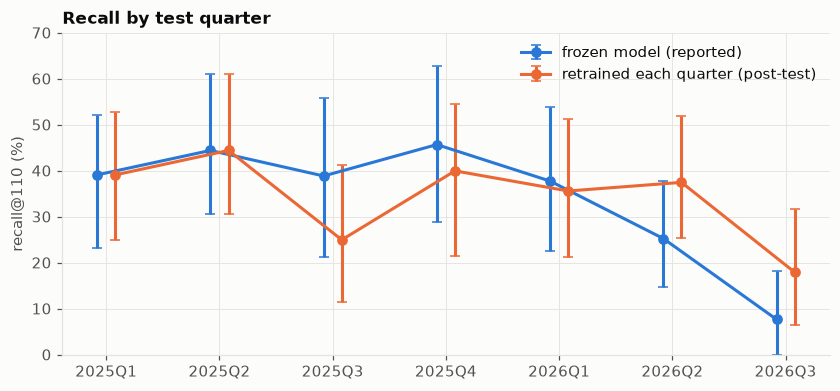

In [3]:
dy = T("06x_drift_by_year").set_index("year"); display(dy.T)
display(T("06x_drift_volume").set_index("period").round(1)); display(T("07_shap_kev_by_year").set_index("year").T.round(2))
roll = T("06x_rolling_retrain"); q = roll[roll["period"].str.contains("Q")].reset_index(drop=True)
display(roll.set_index("period").loc[["2025", "2026", "all test"], ["positives", "frozen @110", "rolling @110", "rolling - frozen (pts)", "diff CI"]])
fig, ax = plt.subplots(figsize=(9, 3.8)); xq = np.arange(len(q))
for nm, c, off in [("frozen", BLUE, -0.08), ("rolling", ORANGE, 0.08)]:
    ax.errorbar(xq + off, q[nm], yerr=[q[nm] - q[f"{nm} lo"], q[f"{nm} hi"] - q[nm]], fmt="o-", color=c, capsize=3, lw=2, label="frozen model (reported)" if nm == "frozen" else "retrained each quarter (post-test)")
ax.set_xticks(xq, q["period"]); ax.set_ylim(0, 70); ax.set_ylabel("recall@110 (%)"); ax.legend(frameon=False); ax.set_title("Recall by test quarter", loc="left"); save(fig, "4_02_drift")

**Takeaway**: **Not everyone dropped**: from 2025 to 2026 the model fell 41.9 → 23.9 and the best rule 29.5 → 20.0, while EPSS stayed at 29.6. Two causes: **volume** (6,800 CVEs a month in 2026, so K = 110 is 1.6% of a month) and **crowding** — CVEs from vendors with KEV history rose from 1,246 to 2,376 a month, and the share of *non-exploited* CVEs pushed up strongly by KEV history went 18.8% → 26.6%. **Retraining every quarter (90-day label delay respected) recovered part of it: 2026 recall 31.3% vs 23.9%** (+7.4 [+0.0, +15.2]); over the whole test period it is a wash (+1.0).

## 4.3 Business impact
Headline = the **frozen** model as evaluated in Phase 6. The retrained-model figures are **post-test exploratory**.
**Edit the assumptions and re-run.**

In [4]:
# ================= ASSUMPTIONS (edit me) =================
HOURS_PER_EMERGENCY_PATCH = 6.0     # out-of-cycle patch: triage, test, change approval, deploy, verify
COST_PER_HOUR_USD = 100.0           # fully loaded analyst/engineer hour
SHARE_OF_FEED = 1.0                 # share of all NVD CVEs that affect your estate (1.0 = whole feed, as studied)
# =========================================================

,period,rule,rule patches / month,rule recall %,GB (frozen) patches / month to match,saved / month (frozen),USD / year (frozen),GB rolling-retrain patches / month to match,"saved / month (retrained, post-test)","USD / year (retrained, post-test)"
0,all test,CVSS>=9 (CNA),384.9,41.2,198.0,186.9,1345680.0,148.0,236.9,1705680.0
1,all test,phrase OR CVSS>=9 (CNA),386.6,47.3,265.0,121.6,875160.0,205.0,181.6,1307160.0
2,2025,CVSS>=9 (CNA),237.5,36.5,83.0,154.5,1112400.0,106.0,131.5,946800.0
3,2025,phrase OR CVSS>=9 (CNA),239.7,45.9,155.0,84.7,609600.0,147.0,92.7,667200.0
4,2026 (Jan-Aug),CVSS>=9 (CNA),606.0,46.7,569.0,37.0,266400.0,302.0,304.0,2188800.0
5,2026 (Jan-Aug),phrase OR CVSS>=9 (CNA),606.9,48.9,630.0,-23.1,-166500.0,330.0,276.9,1993500.0


Same recall as the CVSS>=9 (CNA) rule with fewer emergency patches - sensitivity to hours per patch:


,frozen: hours saved / yr,frozen: USD / yr,"frozen, 2026 rate: USD / yr",retrained (post-test): USD / yr,"retrained, 2026 rate (post-test): USD / yr"
hours per patch,,,,,
2,4486.0,448560.0,88800.0,568560.0,729600.0
4,8971.0,897120.0,177600.0,1137120.0,1459200.0
6,13457.0,1345680.0,266400.0,1705680.0,2188800.0
8,17942.0,1794240.0,355200.0,2274240.0,2918400.0
10,22428.0,2242800.0,444000.0,2842800.0,3648000.0


,patches / month,GB recall %,comparator recall %,extra exploited caught / year
comparison,,,,
"GB vs phrase, then CVSS (CNA) ranking, both at K = 110/month",110.0,33.7,25.2,14.9
"GB vs CVSS (CNA) ranking, both at K = 110/month",110.0,33.7,18.6,26.6
"GB vs CVSS>=9 (CNA) rule, at the rule's own capacity",384.9,51.7,41.2,18.6
"GB vs phrase OR CVSS>=9 (CNA) rule, at the rule's own capacity",386.6,51.7,47.3,7.8


ransomware-linked exploited CVEs (n = 43):


,recall@110 [95% CI],recall@385 [95% CI]
method,,
gradient boosting (headline),42.2 [27–57],65.1 [51–79]
late fusion (alternative),37.2 [24–52],74.4 [59–86]
"phrase, then CVSS (CNA)",26.7 [13–41],55.7 [39–71]
CVSS (CNA) ranking,24.6 [11–39],53.5 [37–70]
"EPSS (first score, <=7 d after pub)",27.9 [15–42],51.2 [36–67]
EPSS (score by day 1),27.9 [15–42],51.2 [36–67]


operating policy (post-test exploratory):


,period,model,fixed K=110: recall %,volume-scaled 4.22%: recall %,"fixed K, same total patches: recall %",scaled: avg patches / month,extra hours / year vs K=110
0,2025,frozen,41.9,49.7,48.1,169.3,4271.2
1,2025,rolling quarterly retrain,37.5,49.1,50.3,169.3,4271.2
2,2026 (Jan-Aug),frozen,23.9,34.1,37.0,287.0,12744.6
3,2026 (Jan-Aug),rolling quarterly retrain,31.3,44.4,45.9,287.0,12744.6
4,all test,frozen,33.7,42.5,41.8,216.4,7660.5
5,all test,rolling quarterly retrain,34.7,46.9,48.0,216.4,7660.5


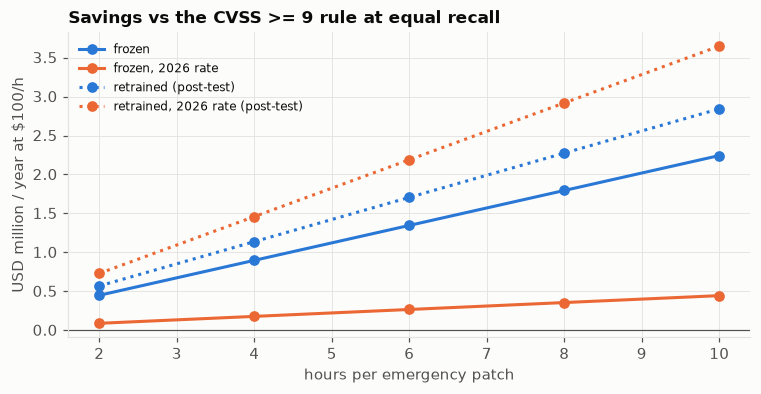

In [5]:
sr = T("07_same_recall"); sc_ = T("07_same_capacity").set_index("comparison"); pol = T("07_policy"); rw = T("07_ransomware")
sr["saved / month (frozen)"] = (sr["rule patches / month"] - sr["GB (frozen) patches / month to match"]) * SHARE_OF_FEED
sr["saved / month (retrained, post-test)"] = (sr["rule patches / month"] - sr["GB rolling-retrain patches / month to match"]) * SHARE_OF_FEED
sr["USD / year (frozen)"] = sr["saved / month (frozen)"] * 12 * HOURS_PER_EMERGENCY_PATCH * COST_PER_HOUR_USD
sr["USD / year (retrained, post-test)"] = sr["saved / month (retrained, post-test)"] * 12 * HOURS_PER_EMERGENCY_PATCH * COST_PER_HOUR_USD
display(sr[["period", "rule", "rule patches / month", "rule recall %", "GB (frozen) patches / month to match", "saved / month (frozen)", "USD / year (frozen)",
            "GB rolling-retrain patches / month to match", "saved / month (retrained, post-test)", "USD / year (retrained, post-test)"]].round(1))
main = sr[(sr["period"] == "all test") & (sr["rule"] == "CVSS>=9 (CNA)")].iloc[0]; y26 = sr[(sr["period"] == "2026 (Jan-Aug)") & (sr["rule"] == "CVSS>=9 (CNA)")].iloc[0]
hours = [2, 4, 6, 8, 10]
sens = pd.DataFrame({"hours per patch": hours,
    "frozen: hours saved / yr": [main["saved / month (frozen)"] * 12 * h for h in hours],
    "frozen: USD / yr": [main["saved / month (frozen)"] * 12 * h * COST_PER_HOUR_USD for h in hours],
    "frozen, 2026 rate: USD / yr": [y26["saved / month (frozen)"] * 12 * h * COST_PER_HOUR_USD for h in hours],
    "retrained (post-test): USD / yr": [main["saved / month (retrained, post-test)"] * 12 * h * COST_PER_HOUR_USD for h in hours],
    "retrained, 2026 rate (post-test): USD / yr": [y26["saved / month (retrained, post-test)"] * 12 * h * COST_PER_HOUR_USD for h in hours]}).set_index("hours per patch")
print("Same recall as the CVSS>=9 (CNA) rule with fewer emergency patches - sensitivity to hours per patch:"); display(sens.round(0))
display(sc_.round(1)); print("ransomware-linked exploited CVEs (n = 43):"); display(rw[rw["subset"] == "ransomware-linked exploited"].set_index("method")[["recall@110 [95% CI]", "recall@385 [95% CI]"]])
print("operating policy (post-test exploratory):"); display(pol.round(1))
fig, ax = plt.subplots(figsize=(8, 3.6))
for c_, col_, ls in [("frozen: USD / yr", BLUE, "-"), ("frozen, 2026 rate: USD / yr", ORANGE, "-"), ("retrained (post-test): USD / yr", BLUE, ":"), ("retrained, 2026 rate (post-test): USD / yr", ORANGE, ":")]:
    ax.plot(sens.index, sens[c_] / 1e6, ls, color=col_, marker="o", lw=2, label=c_.replace(": USD / yr", ""))
ax.axhline(0, color=INK2, lw=0.8); ax.set_xlabel("hours per emergency patch"); ax.set_ylabel(f"USD million / year at ${COST_PER_HOUR_USD:.0f}/h"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Savings vs the CVSS >= 9 rule at equal recall", loc="left"); save(fig, "4_03_business")

**Takeaway**: **Headline (frozen model, test 2025-01 → 2026-08): to match the CVSS ≥ 9 rule's coverage (41.2% of exploited CVEs) the model needs 198 emergency patches a month instead of 385 — ~187 fewer, ~13,500 analyst hours and ~$1.35M a year** at 6 h per patch and $100/h ($0.45M at 2 h to $2.24M at 10 h). At equal capacity it catches **+15 to +27 more exploited CVEs a year** at 110 patches a month, and on ransomware-linked CVEs 42.2% vs 24.6–27.9% for the rules and EPSS (n = 43, wide CIs). **But the saving is concentrated in 2025**: at the 2026 rate the frozen model saves only 37 patches a month ($0.09–0.44M). *Post-test exploratory:* with quarterly retraining the model needs **148 patches a month (~$1.7M a year at 6 h; $0.57–2.84M over 2–10 h)** and keeps the advantage in 2026 (302 vs 606 patches).

## 4.4 Recommendations for the CISO
1. **Replace "patch every CVSS ≥ 9" with a model-ranked emergency list** (gradient boosting on day-0 data): same workload,
   more exploited CVEs caught (33.7% vs 25.2% of the best rule at 110 a month), or the same coverage with about half the patches.
2. **Retrain every quarter** (respecting the 90-day label delay) and **review capacity against CVE volume each quarter**
   (e.g. ~4.2% of each month's CVEs): without both, 2026 showed the advantage can vanish (post-test exploratory evidence).
3. **Use EPSS as a second opinion, not the primary ranking**: it is a next-day signal, ranks its very top slightly better at
   ≤ 50 patches a month, and much of its apparent strength comes from CVEs already in KEV (14.6% vs 30.4% on the rest).
4. **Track live**: each month, recall on newly KEV-listed CVEs and the share of PATCH NOW CVEs from KEV-history vendors
   (the 2026 crowding signal). Every ranked CVE comes with its top reasons (notebook 5).

## 4.5 Limitations
* **The baseline policy is assumed.** "Patch CVSS ≥ 9" is common severity-based practice, not a verified policy of a specific
  organisation. The conclusion does not rest on it: the model leads every day-0 rule at every K from 10 to 1,000 patches a
  month and each rule at its own capacity (CVSS ≥ 9, CVSS ≥ 7, phrase-or-CVSS ≥ 9, hindsight CVSS ≥ 9); only EPSS (with a
  one-day lookahead) is ahead, and only at ≤ 50 patches a month (notebook 3).
* **Label = CISA KEV within 90 days**: CISA's selection; exploits never reported to CISA count as "not exploited".
* **Day-0 is approximate**: CNAs later changed their own CVSS for 5.5% of exploited vs 1.9% of other CVEs (−0.8 points);
  description edits are label-correlated (history audited for a sample).
* **EPSS comparison**: lookahead, different target, v3→v4 switch, EPSS's use of KEV is an assumption.
* **Drift and small numbers**: 294 exploited test CVEs; quarterly CIs ±15–20 points; ransomware subset 43 CVEs.
* **Money**: whole NVD feed; a real organisation sees only its own estate (`SHARE_OF_FEED`); hours per patch is an assumption (2–10 h shown).
* **Probabilities** are indicative (over-prediction on average after the base rate fell).